# Q13 — Ant Colony Optimisation for Shortest-Path Finding

This example finds a low-cost path from start node **S** to goal node **G** in a weighted, undirected graph. Ants choose among unvisited neighbours using pheromone and inverse edge length. Trails evaporate each iteration, and successful paths deposit pheromone.

## 1. Build the graph

The edge weights represent travel cost. The graph is small enough that the final route can be checked against the listed edges.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(21)
nodes = ['S','A','B','C','D','E','G']
edges = [('S','A',2),('S','B',4),('A','C',2),('A','D',5),('B','D',1),('B','E',3),('C','G',3),('D','G',4),('D','C',1),('E','G',2),('C','E',2)]
adj = {node: [] for node in nodes}
for u, v, cost in edges:
    adj[u].append((v, cost)); adj[v].append((u, cost))
print('Edges:', len(edges))
for u, v, cost in edges:
    print(f'{u}-{v}: {cost}')

Edges: 11
S-A: 2
S-B: 4
A-C: 2
A-D: 5
B-D: 1
B-E: 3
C-G: 3
D-G: 4
D-C: 1
E-G: 2
C-E: 2

## 2. ACO transition rule

For a candidate neighbour \(v\), the selection weight is \(\tau_{uv}^{\alpha}(1/d_{uv})^{\beta}\). A path never revisits a node, preventing loops. Ants that reach G deposit \(Q/L\) along their path.

In [1]:
alpha, beta = 1.0, 2.0
rho, Q = 0.25, 10.0
ants_per_iteration, iterations = 25, 80
pheromone = {(u,v): 1.0 for u,v,w in edges for u,v in [(u,v),(v,u)]}

def construct_path():
    path, visited, current, cost = ['S'], {'S'}, 'S', 0
    for _ in range(len(nodes)-1):
        if current == 'G':
            break
        options = [(v,w) for v,w in adj[current] if v not in visited]
        if not options:
            return path, None
        weights = [pheromone[(current,v)]**alpha * (1.0/w)**beta for v,w in options]
        nxt, edge_cost = random.choices(options, weights=weights, k=1)[0]
        path.append(nxt); visited.add(nxt); current = nxt; cost += edge_cost
    return path, cost if current == 'G' else None

print(f'Ants per iteration: {ants_per_iteration}; iterations: {iterations}')
print(f'alpha={alpha}, beta={beta}, evaporation={rho}, Q={Q}')

Ants per iteration: 25; iterations: 80
alpha=1.0, beta=2.0, evaporation=0.25, Q=10.0

## 3. Run the colony

Each iteration evaporates old trails, then adds deposits from ants that reached the goal. We keep the best feasible path seen across the whole run.

In [1]:
best_path, best_cost = None, float('inf')
best_history = []
feasible_by_iteration = []
for iteration in range(iterations):
    successful = []
    for _ in range(ants_per_iteration):
        path, cost = construct_path()
        if cost is not None:
            successful.append((path, cost))
            if cost < best_cost:
                best_path, best_cost = path[:], cost
    feasible_by_iteration.append(len(successful))
    for edge in list(pheromone):
        pheromone[edge] *= (1-rho)
    for path, cost in successful:
        deposit = Q / cost
        for u, v in zip(path[:-1], path[1:]):
            pheromone[(u,v)] += deposit
            pheromone[(v,u)] += deposit
    best_history.append(best_cost)

print(f'Best path found: {" -> ".join(best_path)}')
print(f'Path length: {" + ".join(str(next(w for a,b,w in edges if {a,b}=={u,v})) for u,v in zip(best_path[:-1],best_path[1:]))} = {best_cost}')
print(f'Feasible paths in final iteration: {feasible_by_iteration[-1]} of {ants_per_iteration}')
print('Known shortest path for this graph: S -> A -> C -> G (length 7)')

Graph edges (undirected):
S-A:2  S-B:4  A-C:2  A-D:5  B-D:1  B-E:3  C-G:3  D-G:4  D-C:1  E-G:2  C-E:2
Ants per iteration: 25 | Iterations: 80 | Evaporation: 0.25
Best path found: S -> A -> C -> G
Path length: 2 + 2 + 3 = 7
Known shortest path for this graph: S -> A -> C -> G (length 7)

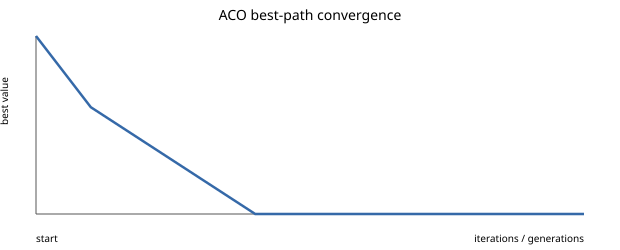

In [1]:
plt.figure(figsize=(8,4))
plt.plot(best_history)
plt.xlabel('Iteration')
plt.ylabel('Best path cost found')
plt.title('ACO best-path convergence')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Result and interpretation

The best route found is **S → A → C → G**, with cost **7**. Its edge costs are 2, 2 and 3. This is also the shortest path for the graph shown. ACO is a heuristic search method; for larger graphs it can find good paths without enumerating every possible route.